## 1. Import Library

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
import keras
from sklearn.model_selection import train_test_split

keras.utils.set_random_seed(42)   # hasil training bisa diulang

## 2. Load Dataset

In [2]:
PATH = "./Dataset/"
CLASS_NAMES = sorted(os.listdir(PATH))   # sorted -> urutan label pasti (alfabet)
print("Classes:", CLASS_NAMES)

Classes: ['Broccoli', 'Carrot', 'Cucumber', 'Tomato']


In [3]:
rows, cols = 224, 224
x, y = [], []

for label, class_name in enumerate(CLASS_NAMES):          # label: 0, 1, 2, 3
    for img_name in os.listdir(PATH + class_name):
        img = keras.utils.load_img(f"{PATH}{class_name}/{img_name}",
                                   target_size=(rows, cols), color_mode="grayscale")
        x.append(keras.utils.img_to_array(img))           # (224, 224, 1)
        y.append(label)

x, y = np.array(x), np.array(y)

# Random shuffle: satu urutan acak dipakai untuk x dan y agar tetap berpasangan
idx = np.random.permutation(len(x))
x, y = x[idx], y[idx]

print(x.shape, y.shape)
print(np.unique(y, return_counts=True))

(2000, 224, 224, 1) (2000,)
(array([0, 1, 2, 3]), array([500, 500, 500, 500]))


## 3. Split Dataset (80 / 10 / 10)

In [4]:
x_train, x_temp, y_train, y_temp = train_test_split(x, y, test_size=0.2, random_state=42, stratify=y)
x_val, x_test, y_val, y_test = train_test_split(x_temp, y_temp, test_size=0.5, random_state=42, stratify=y_temp)

print(len(x_train), len(x_val), len(x_test))

1600 200 200


## 4. Data Preprocessing

In [5]:
# 1. reshape (jumlah gambar, tinggi, lebar, channel) | 2. float32 | 3. normalisasi /255
x_train = x_train.reshape(-1, rows, cols, 1).astype("float32") / 255.0
x_val   = x_val.reshape(-1, rows, cols, 1).astype("float32") / 255.0
x_test  = x_test.reshape(-1, rows, cols, 1).astype("float32") / 255.0

# 4. one-hot encoding label
NUM_CLASSES = len(CLASS_NAMES)
y_train = keras.utils.to_categorical(y_train, NUM_CLASSES)
y_val   = keras.utils.to_categorical(y_val, NUM_CLASSES)
y_test  = keras.utils.to_categorical(y_test, NUM_CLASSES)

## 5. Arsitektur DCNN

In [6]:
model = keras.Sequential([
    # Input layer
    keras.layers.Input(shape=(rows, cols, 1)),

    # Hidden layer: Conv -> Pool -> Conv -> Conv -> Pool -> Flatten
    keras.layers.Conv2D(6, (5, 5), activation="relu"),
    keras.layers.MaxPooling2D(pool_size=(2, 2), strides=2),
    keras.layers.Conv2D(16, (5, 5), activation="relu"),
    keras.layers.Conv2D(16, (5, 5), activation="relu"),
    keras.layers.MaxPooling2D(pool_size=(2, 2), strides=2),
    keras.layers.Flatten(),

    # Output layer: Dense ReLU -> Dense Softmax
    keras.layers.Dense(120, activation="relu"),
    keras.layers.Dense(NUM_CLASSES, activation="softmax"),
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 220, 220, 6)    │           156 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 110, 110, 6)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 106, 106, 16)   │         2,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 102, 102, 16)   │         6,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 51, 51, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 41616)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 120)            │     4,994,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           484 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,003,512 (19.09 MB)

 Trainable params: 5,003,512 (19.09 MB)

 Non-trainable params: 0 (0.00 B)

## 6. Training

In [7]:
model.compile(optimizer="adam", loss="categorical_crossentropy", metrics=["accuracy"])

history = model.fit(x_train, y_train, batch_size=32, epochs=10,
                    validation_data=(x_val, y_val))

Epoch 1/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 13s 189ms/step - accuracy: 0.4050 - loss: 1.3149 - val_accuracy: 0.5300 - val_loss: 1.0321
Epoch 2/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 9s 169ms/step - accuracy: 0.7125 - loss: 0.6977 - val_accuracy: 0.7650 - val_loss: 0.6894
Epoch 3/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 8s 167ms/step - accuracy: 0.8512 - loss: 0.3845 - val_accuracy: 0.7950 - val_loss: 0.6364
Epoch 4/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 9s 170ms/step - accuracy: 0.9013 - loss: 0.2499 - val_accuracy: 0.7200 - val_loss: 1.0699
Epoch 5/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 9s 173ms/step - accuracy: 0.9325 - loss: 0.1970 - val_accuracy: 0.8050 - val_loss: 0.7154
Epoch 6/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 10s 193ms/step - accuracy: 0.9675 - loss: 0.1088 - val_accuracy: 0.7850 - val_loss: 0.8969
Epoch 7/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 10s 203ms/step - accuracy: 0.9750 - loss: 0.1063 - val_accuracy: 0.8450 - val_loss: 0.7055
Epoch 8/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 10s 199ms/step - accuracy: 0.9750 - loss: 0.0911 - val_accuracy

## 7. Predict & Evaluate

In [8]:
# Predict: probabilitas per kelas -> ambil kelas terbesar
pred = model.predict(x_test)
pred_class = np.argmax(pred, axis=1)
true_class = np.argmax(y_test, axis=1)

pred_loss = keras.losses.categorical_crossentropy(y_test, pred).numpy().mean()
pred_acc = (pred_class == true_class).mean()
print(f"[Predict]  Loss: {pred_loss:.4f} | Accuracy: {pred_acc:.4f}")

7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 89ms/step
[Predict]  Loss: 1.6517 | Accuracy: 0.6950


In [9]:
# Evaluate: model.evaluate mengembalikan [loss, accuracy]
loss, acc = model.evaluate(x_test, y_test)
print(f"[Evaluate] Loss: {loss:.4f} | Accuracy: {acc:.4f}")

7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 72ms/step - accuracy: 0.6950 - loss: 1.6926
[Evaluate] Loss: 1.6926 | Accuracy: 0.6950


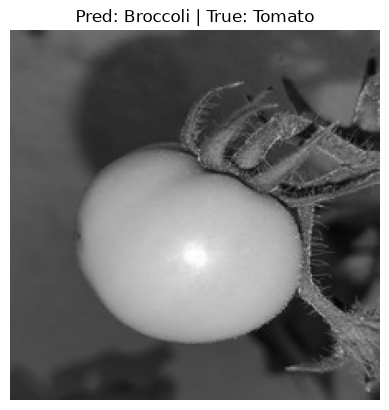

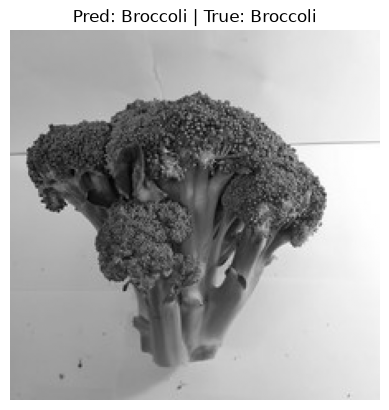

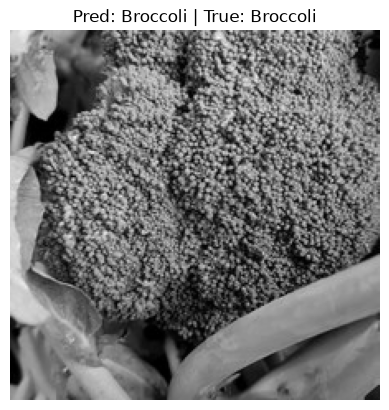

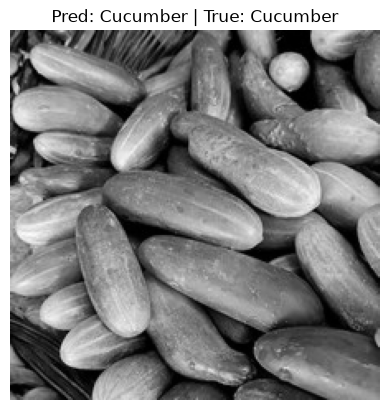

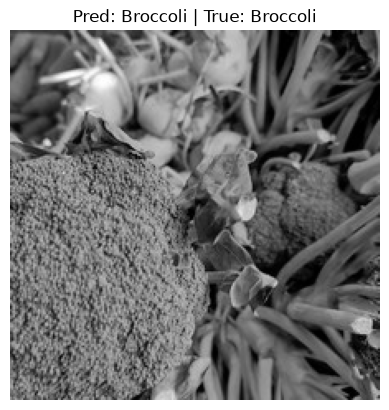

In [10]:
# Tampilkan 5 gambar test: prediksi vs label asli
for i in range(5):
    pred_name = CLASS_NAMES[np.argmax(pred[i])]
    true_name = CLASS_NAMES[np.argmax(y_test[i])]

    plt.imshow(x_test[i].squeeze(), cmap="gray")
    plt.title(f"Pred: {pred_name} | True: {true_name}")
    plt.axis("off")
    plt.show()

## 8. Plot Evaluation Metrics

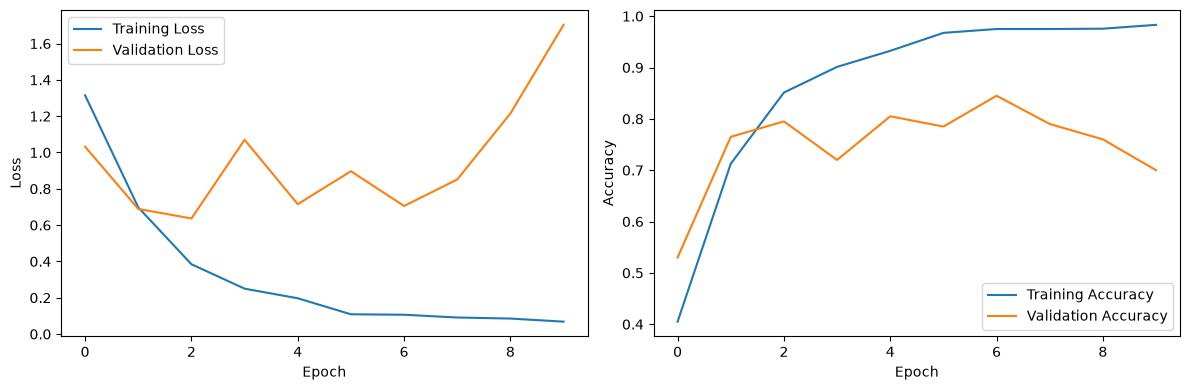

In [11]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch"); plt.ylabel("Accuracy"); plt.legend()

plt.tight_layout()
plt.show()